# Machine Learning Lab
## Experiment 04: Multiple Linear Regression using Gradient Descent & Effect of Feature Scaling

### 1. Aim
To implement Multiple Linear Regression using Gradient Descent on a house-price dataset and compare the convergence behaviour of Gradient Descent with and without feature scaling.

### 8.1 Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

### 8.2 Step 2: Load the Dataset
Load the same dataset used in Experiment 03.

In [2]:
df = pd.read_csv(
    "ML_Lab_Multiple_Linear_Regression_House_Prices.csv"
)
print(df.head())

   Area_sqft  Bedrooms  Bathrooms  ...  Floor  Balconies  Price_Lakhs
0       1726         2          2  ...     10          3       168.54
1       2059         2          1  ...     10          3       185.35
2       1460         4          4  ...      0          3       183.25
3       1894         4          4  ...      0          0       187.83
4       1730         1          1  ...      1          2       158.35

[5 rows x 9 columns]


### 8.3 Step 3: Select Features and Target
Use the same eight input features from Experiment 03.

In [3]:
features = [
    'Area_sqft',
    'Bedrooms',
    'Bathrooms',
    'Age_years',
    'Distance_to_Metro_km',
    'Parking',
    'Floor',
    'Balconies'
]
X = df[features].values
y = df['Price_Lakhs'].values

### 8.4 Step 4: Inspect Feature Ranges
Before applying scaling, inspect the numerical range of each feature.

In [4]:
print(df[features].describe())

         Area_sqft    Bedrooms   Bathrooms  ...     Parking      Floor   Balconies
count   100.000000  100.000000  100.000000  ...  100.000000  100.00000  100.000000
mean   1572.580000    2.970000    2.780000  ...    0.720000    4.44000    1.400000
std     532.161652    1.473366    1.467355  ...    0.451261    3.27932    1.073087
min     613.000000    1.000000    1.000000  ...    0.000000    0.00000    0.000000
25%    1149.000000    1.750000    1.000000  ...    0.000000    1.00000    0.000000
50%    1598.000000    3.000000    3.000000  ...    1.000000    4.00000    1.000000
75%    2019.000000    4.000000    4.000000  ...    1.000000    7.00000    2.000000
max    2499.000000    5.000000    5.000000  ...    1.000000   10.00000    3.000000

[8 rows x 8 columns]


### 9.1 Step 5: Initialize Parameters
Initialize the model parameters with zeros.

In [5]:
m = len(y)
weights = np.zeros(X.shape[1])
bias = 0
learning_rate = 0.0000001
iterations = 1000

### 9.2 Step 6: Implement Gradient Descent

In [6]:
cost_history = []
for i in range(iterations):
    # Prediction
    y_pred = X @ weights + bias
    # Error
    error = y_pred - y
    # Individual loss
    individual_loss = 0.5 * (error ** 2)
    # Cost
    cost = np.mean(individual_loss)
    # Store cost
    cost_history.append(cost)
    # Gradients
    dw = (1/m) * (X.T @ error)
    db = (1/m) * np.sum(error)
    # Parameter update
    weights = weights - learning_rate * dw
    bias = bias - learning_rate * db

### 9.3 Step 7: Display Final Cost

In [7]:
print("Final Cost:", cost_history[-1])

Final Cost: 501.1409858199032


### 9.4 Step 8: Plot Cost vs Iteration

<ipython-input-1-784da1c63394>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


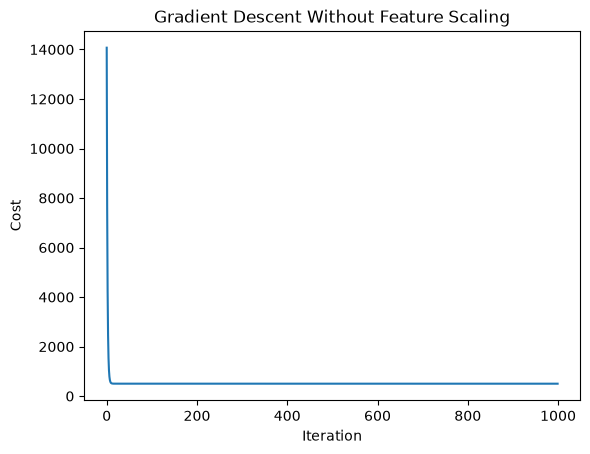

In [8]:
plt.plot(cost_history)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title(
    "Gradient Descent Without Feature Scaling"
)
plt.show()

### 10.1 Step 9: Apply Standardization
In the second experiment, standardize the input features before applying Gradient Descent.

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:5])

[[ 0.28974824 -0.66167301 -0.53424658 -1.53713872  1.53118203  0.62360956
   1.70401496  1.4985373 ]
 [ 0.91865036 -0.66167301 -1.21917808 -0.91857183  0.48492703  0.62360956
   1.70401496  1.4985373 ]
 [-0.21261802  0.70260124  0.83561644  0.78248712  0.04695982  0.62360956
  -1.36076014  1.4985373 ]
 [ 0.60703219  0.70260124  0.83561644  1.24641229  0.53359005 -1.60356745
  -1.36076014 -1.31122014]
 [ 0.29730262 -1.34381014 -1.21917808 -1.07321356 -0.24501832  0.62360956
  -1.05428263  0.56195149]]


### 10.2 Step 10: Reinitialize Parameters
The parameters must be initialized again before starting the second experiment.

In [10]:
weights = np.zeros(X_scaled.shape[1])
bias = 0
learning_rate = 0.01
iterations = 1000

### 10.3 Step 11: Implement Gradient Descent on Scaled Data

In [11]:
cost_history_scaled = []
for i in range(iterations):
    # Prediction
    y_pred = X_scaled @ weights + bias
    # Error
    error = y_pred - y
    # Individual loss
    individual_loss = 0.5 * (error ** 2)
    # Cost
    cost = np.mean(individual_loss)
    # Store cost
    cost_history_scaled.append(cost)
    # Gradients
    dw = (1/m) * (X_scaled.T @ error)
    db = (1/m) * np.sum(error)
    # Parameter update
    weights = weights - learning_rate * dw
    bias = bias - learning_rate * db

### 10.4 Step 12: Plot Cost vs Iteration

<ipython-input-1-70983e3a9d0d>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


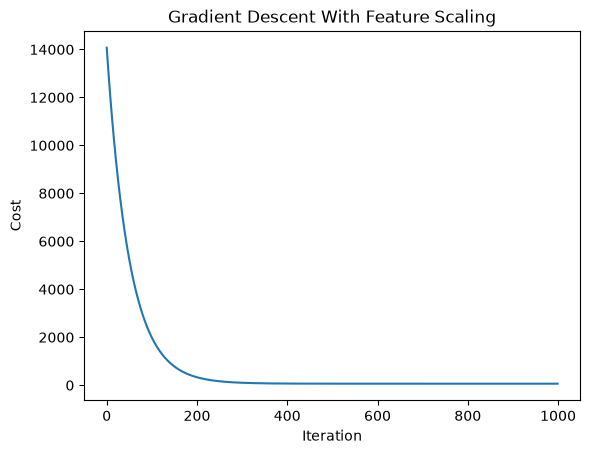

In [12]:
plt.plot(cost_history_scaled)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title(
    "Gradient Descent With Feature Scaling"
)
plt.show()

### 11. Comparison of Scaling and Convergence
Compare the convergence behaviour of Gradient Descent with and without feature scaling.

<ipython-input-1-dcd7841dcdf4>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


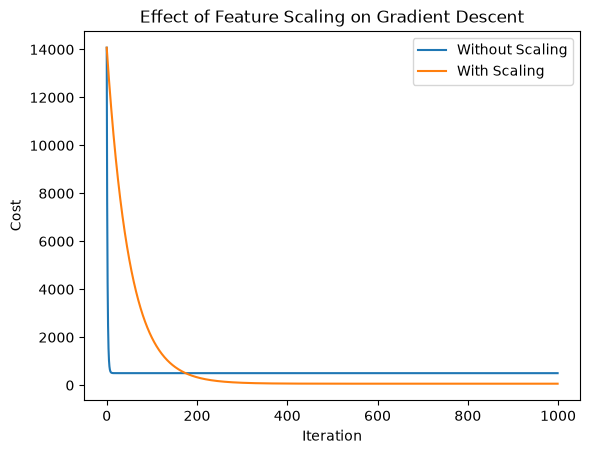

In [13]:
plt.plot(
    cost_history,
    label="Without Scaling"
)
plt.plot(
    cost_history_scaled,
    label="With Scaling"
)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title(
    "Effect of Feature Scaling on Gradient Descent"
)
plt.legend()
plt.show()